<a href="https://colab.research.google.com/github/mashadiyevasabina/AB-Test.Project/blob/main/Megaline_Project_jpynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Megaline Tarif Planlarının Təhlili: Gəlir və Müştəri Davranışlarının Analizi

##Megaline Şirkəti müştərilərinə iki "əvvəlcədən ödənişli" plan təklif edir: Surf və Ultimate. Kommersiya şöbəsi reklam büdcəsini tənzimləmək üçün hansı planların daha çox gəlir gətirdiyini bilmək istəyir.






## 📌 Layihənin əsas KPİ-ları və Təhqiqat Hədəfləri:

1. **Aylıq Orta Gəlir (ARPU - Average Revenue Per User):** Surf və Ultimate tarif planlarının istifadəçi başına gətirdiyi orta gəlirin müqayisəsi.
2. **Limitdən Kənar Gəlir Payı:** Müştərilərin əsas abunə haqqından əlavə ödədikləri xidmətlərin (dəqiqə, meqabayt, SMS) ümumi gəlirdəki payının təhlili.
3. **Resurs İstehlakı Həcmi:** Hər bir tarif üzrə zəng müddəti (dəqiqə), internet trafiki (GB) və SMS istifadəsinin paylanması.
4. **Tarif Üzrə Müştəri Retention / Churn Rejimi:** 500 istifadəçi arasında planları tərk edən (churn) müştərilərin nisbəti və aktiv istifadəçi davranışı.
5. **Hipotezlərin Yoxlanılması (Statistik Testlər):**
   - Surf və Ultimate tariflərinin orta gəlirləri arasında statistik əhəmiyyətli fərqin olub-olmaması.
   - NY-NJ regionundakı istifadəçilərin gəlirinin digər regionlardan fərqlənməsi.

## 📊 Dataset Cədvəlləri və Sütun İzahları:

* **`plans` (Tarif şərtləri cədvəli):**
  - `plan_name`: Tarif planının adı (*Surf* və ya *Ultimate*).
  - `usd_monthly_pay`: Aylıq abunə haqqı ($).
  - `minutes_included` / `messages_included` / `mb_per_month_included`: Tarife daxil olan dəqiqə, SMS və MB limitləri.
  - `usd_per_minute` / `usd_per_message` / `usd_per_gb`: Limit keçildikdə hər əlavə dəqiqə, SMS və GB üçün ödəniş.

* **`users` (Müştəri məlumatları cədvəli):**
  - `user_id`: İstifadəçinin unikal identifikasiya nömrəsi.
  - `first_name` / `last_name` / `age` / `city`: Müştərinin adı, soyadı, yaşı və yaşadığı şəhər.
  - `reg_date` / `churn_date`: Tarifə qoşulma və abunəlikdən çıxma tarixləri.
  - `plan`: İstifadəçinin seçdiyi tarif planı.
  - `state`: Şəhər adından çıxarılmış 2 hərflü ştat kodu.

* **`calls` (Zəng tarixçəsi cədvəli):**
  - `id`: Hər bir zəngin unikal kodu.
  - `user_id`: Zəng edən müştərinin ID-si.
  - `call_date`: Zəngin edildiyi tarix.
  - `duration`: Zəngin müddəti (dəqiqə ilə).

* **`internet` (İnternet istifadə tarixçəsi cədvəli):**
  - `id`: İnternet sessiyasının unikal kodu.
  - `user_id`: İnternetdən istifadə edən müştərinin ID-si.
  - `session_date`: İnternetə daxil olunan tarix.
  - `mb_used`: İstifadə olunmuş internet həcmi (MB ilə).

* **`messages` (SMS tarixçəsi cədvəli):**
  - `id`: SMS-in unikal kodu.
  - `user_id`: SMS göndərən müştərinin ID-si.
  - `message_date`: SMS-in göndərildiyi tarix.

## Kitabxanalar

In [78]:

import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Datanın yüklənməsi

In [79]:

calls         = pd.read_csv("/content/drive/MyDrive/Megaline_Project/megaline_calls.csv")
internet       = pd.read_csv("/content/drive/MyDrive/Megaline_Project/megaline_internet.csv")
messages    = pd.read_csv("/content/drive/MyDrive/Megaline_Project/megaline_messages.csv")
plans         = pd.read_csv("/content/drive/MyDrive/Megaline_Project/megaline_plans.csv")
users = pd.read_csv("/content/drive/MyDrive/Megaline_Project/megaline_users.csv")



## Datanın analizə hazırlanması

## Plans

In [80]:
# Plans cədvəli haqqında informasiya alaq
plans.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 260.0+ bytes


### Plan cədvəlindəki plan_name sütununun tipini stringə çevirək

In [81]:
plans['plan_name'] = plans['plan_name'].astype("string")
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      string 
dtypes: float64(2), int64(5), string(1)
memory usage: 260.0 bytes


In [82]:
# Plans cədvəlinə ümumi baxış edək
plans


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


###Cədvəldə cəmi 2 sətir var və heç bir missing valuelər yoxdur. Sütunlar tariflərin limitlərini və limitdən kənar istifadə üçün qiymətləri göstərir:

##surf: 20$ aylıq ödəniş, 50 SMS, 15,360 MB (15 GB), 500 dəqiqə.

##ultimate: 70$ aylıq ödəniş, 1000 SMS, 30,720 MB (30 GB), 3000 dəqiqə.

## Users

In [83]:
# Print the general/summary information about the users' DataFrame
users.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


### sadəcə churn_date sütununda 34 ədəd missing valuelər var bu sütun isə istifadəçinin tarifdən çıxış vaxtını göstərən bir sütün olduğu üçün çıxış tarixi boş olan istifadəçilər hələ də paketdən istifadə edən aktiv istifadəçilərdir.

In [84]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaN
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaN
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaN


###Sütun tiplərində düzəliş edək: reg_date ve churn_date swtunları taarif planına giriş və çıxış vaxtlarını göstərdiyi üçün datetime tipinə keçək ki daha sonra bu iki vaxt arasındakı zaman dilimini hesablamaq bizə rfahat olsun, dah sonra ad  soy ad bildirən sütunları və şəhər adlarını plan adları sütünlarını string tipinə çevirək

In [85]:
users['reg_date'] = pd.to_datetime(users['reg_date'])
users['churn_date'] = pd.to_datetime(users['churn_date'])
users['first_name']=users['first_name'].astype("string")
users['last_name']=users['last_name'].astype("string")
users['city']=users['city'].astype("string")
users['plan']=users['plan'].astype("string")
users.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    string        
 2   last_name   500 non-null    string        
 3   age         500 non-null    int64         
 4   city        500 non-null    string        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    string        
 7   churn_date  34 non-null     datetime64[ns]
dtypes: datetime64[ns](2), int64(2), string(4)
memory usage: 31.4 KB


###Dublikatları yoxlayaq

In [86]:
users.duplicated().sum()

np.int64(0)

In [87]:
users['user_id'].duplicated().sum()

np.int64(0)

### Nə ümumi cədvəldə nə də user_id sütunund dublikatlar yoxdur

### Ay sütununu kənara çıxaraq

In [88]:
users['reg_month']=users['reg_date'].dt.month
users
users['churn_month']=users['churn_date'].dt.month
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,reg_month,churn_month
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaT,12,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaT,10,NaN
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaT,1,NaN
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaT,5,NaN


In [89]:
#Users cədvəlinə baxaq

users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,reg_month,churn_month
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaT,12,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaT,10,NaN
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaT,1,NaN
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaT,5,NaN


### datada bir narahat edici məqam city sütunudur ki orada şəhər adları çox uzun ifadə olunub. tərkibində həm şəhər adları, həm ştat qısaltması  həm də metropoliten ərazi abreviaturası (MSA) var.

###Analizdə (xüsusən də regional müqayisələr apararkən və ya NY-NJ regionu ilə digər ştatları müqayisə edərkən) bu mətnlər çətinlik yarada bilər.

In [90]:
# Mətndən 2 hərfli ştat kodunu çıxarıb 'state' adında yeni sütun yaradırıq
users['state'] = users['city'].str.extract(r',\s*([A-Z]{2})')

# Yoxlamaq üçün:
print(users[['city', 'state']].head())

                                    city state
0  Atlanta-Sandy Springs-Roswell, GA MSA    GA
1        Seattle-Tacoma-Bellevue, WA MSA    WA
2   Las Vegas-Henderson-Paradise, NV MSA    NV
3                          Tulsa, OK MSA    OK
4        Seattle-Tacoma-Bellevue, WA MSA    WA


In [91]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,reg_month,churn_month,state
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaT,12,NaN,GA
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN,WA
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaT,10,NaN,NV
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaT,1,NaN,OK
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaT,5,NaN,WA


## Calls

In [92]:
# Calls cədvəlinin infosuna baxaq
calls.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


### Cədvəldə heç bir sütunda missing valuelər yoxdur. sadəcə id sütununu integer tipnə, call_date sütununu datetime tipinə keçirək

In [93]:
calls['id']=calls['id'].astype('int')
calls['call_date']=pd.to_datetime(calls['call_date'])

calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  int64         
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 4.2 MB


In [94]:
# Calls cədvəlinə ümumi baxış edək
calls.head()

,id,user_id,call_date,duration
0,100093,1000,2018-12-27,8.52
1,1000145,1000,2018-12-27,13.66
2,1000247,1000,2018-12-27,14.48
3,1000309,1000,2018-12-28,5.76
4,1000380,1000,2018-12-30,4.22


### Megaline şirkəti zəng saniyələrini dəqiqələrə, meqabaytları isə giqabaytlara doğru yuxarı yuvarlaqlaşdırır:Hər bir fərdi zəng yuxarı yuvarlaqlaşdırılır. Zəng cəmi 1 saniyə sürsə bile, 1 dəqiqə kimi hesablanır.calls cədvəlində duration sütununu yuxarı tam ədədə yuvarlaqlaşdıraq.

In [95]:
calls['duration'] = np.ceil(calls['duration']).astype('int')
calls.head()


,id,user_id,call_date,duration
0,100093,1000,2018-12-27,9
1,1000145,1000,2018-12-27,14
2,1000247,1000,2018-12-27,15
3,1000309,1000,2018-12-28,6
4,1000380,1000,2018-12-30,5


### calls messages ve internet cedvellerinin her ucunde id swtunu var ve bunlari ferqlendirmek ucun adlarini deyisek

In [96]:
calls=calls.rename(columns={'id':'call_id'})
calls.head()

,call_id,user_id,call_date,duration
0,100093,1000,2018-12-27,9
1,1000145,1000,2018-12-27,14
2,1000247,1000,2018-12-27,15
3,1000309,1000,2018-12-28,6
4,1000380,1000,2018-12-30,5


### Dublikatlari yoxlayaq

In [97]:
calls.duplicated().sum()

np.int64(0)

In [98]:
calls['call_id'].duplicated().sum()

np.int64(0)

### Dublikatlar yoxdur

### Növbəti mərhələlərdə aylıq analizlər aparacağımız üçün cədvəldə ayı ayrı sütun kimi çıxaraq


In [99]:
calls['month'] =calls['call_date'].dt.month
calls.head()

,call_id,user_id,call_date,duration,month
0,100093,1000,2018-12-27,9,12
1,1000145,1000,2018-12-27,14,12
2,1000247,1000,2018-12-27,15,12
3,1000309,1000,2018-12-28,6,12
4,1000380,1000,2018-12-30,5,12


## Messages

In [100]:
# Messages cədvəlinin infosuna baxaq
messages.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


### bu cədvəldə də missing value yoxdur və sadəcə id və message _date sütunlarının tipini dəyişək

In [101]:
messages['id']=messages['id'].astype('int')
messages['message_date']=pd.to_datetime(messages['message_date'])
messages.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  int64         
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(2)
memory usage: 1.7 MB


### Id sutunun adini deyisek ve message_id qoyaq

In [102]:
messages=messages.rename(columns={'id':'message_id'})
messages.head()

,message_id,user_id,message_date
0,1000125,1000,2018-12-27
1,1000160,1000,2018-12-31
2,1000223,1000,2018-12-31
3,1000251,1000,2018-12-27
4,1000255,1000,2018-12-26


### Dublikatlari yoxlayaq

In [103]:
messages.duplicated().sum()

np.int64(0)

In [104]:
messages['message_id'].duplicated().sum()

np.int64(0)

### duplikatlar yoxdur

### Ay swtununu kənara çıxaraq

In [105]:
messages['month'] = messages['message_date'].dt.month


In [106]:
#mesages cedveline umumi baxis edek
messages.head()


,message_id,user_id,message_date,month
0,1000125,1000,2018-12-27,12
1,1000160,1000,2018-12-31,12
2,1000223,1000,2018-12-31,12
3,1000251,1000,2018-12-27,12
4,1000255,1000,2018-12-26,12


## Internet

In [107]:
#İnternet cedvelinin infosuna baxaq
internet.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


### Bu cədvəldə misisng valuelər yoxdur amma sütun tiplərini dəyişək

In [108]:
internet['id']=internet['id'].astype('int')
internet['session_date']=pd.to_datetime(internet['session_date'])
internet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  int64         
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 3.2 MB


### id sutununun adini deyisek

In [109]:
internet=internet.rename(columns={'id':'internet_id'})
internet.head()

,internet_id,user_id,session_date,mb_used
0,100013,1000,2018-12-29,89.86
1,1000204,1000,2018-12-31,0.00
2,1000379,1000,2018-12-28,660.40
3,1000413,1000,2018-12-26,270.99
4,1000442,1000,2018-12-27,880.22


###Dublikatlari yoxlayaq

In [110]:
internet.duplicated().sum()

np.int64(0)

In [111]:
internet['internet_id'].duplicated().sum()

np.int64(0)

###dublikatlar yoxdur

### Ay swtununu kənara çıxaraq

In [112]:
internet['month'] = internet['session_date'].dt.month
internet.head()

,internet_id,user_id,session_date,mb_used,month
0,100013,1000,2018-12-29,89.86,12
1,1000204,1000,2018-12-31,0.00,12
2,1000379,1000,2018-12-28,660.40,12
3,1000413,1000,2018-12-26,270.99,12
4,1000442,1000,2018-12-27,880.22,12


In [113]:
# İnternet cedveline umumi baxis edek
internet.head()



,internet_id,user_id,session_date,mb_used,month
0,100013,1000,2018-12-29,89.86,12
1,1000204,1000,2018-12-31,0.00,12
2,1000379,1000,2018-12-28,660.40,12
3,1000413,1000,2018-12-26,270.99,12
4,1000442,1000,2018-12-27,880.22,12


In [114]:
# plans cədvəlini yeniden getirek
plans



,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


##İstifadəçi başına ümumi məlumatlar



In [115]:
# Hər istifadəçi tərəfindən ayda edilən zənglərin sayını hesablayın. Nəticəni yadda saxlayın.

calls_number=calls.groupby(['user_id','month'])['call_id'].count().reset_index()
calls_number = calls_number.rename(columns={'call_id': 'call_per_month'})
calls_number.head()


,user_id,month,call_per_month
0,1000,12,16
1,1001,8,27
2,1001,9,49
3,1001,10,65
4,1001,11,64


In [116]:

# Hər istifadəçinin ayda sərf etdiyi dəqiqələrin miqdarını hesablayın. Nəticəni yadda saxlayın.
duration_sum=calls.groupby(['user_id','month'])['duration'].sum().reset_index()
duration_sum = duration_sum.rename(columns={'duration': 'minutes_per_month'})
duration_sum.head()




,user_id,month,minutes_per_month
0,1000,12,124
1,1001,8,182
2,1001,9,315
3,1001,10,393
4,1001,11,426


In [117]:
# Hər istifadəçi tərəfindən ayda göndərilən mesajların sayını hesablayın. Nəticəni yadda saxlayın.
messages_count=messages.groupby(['user_id','month'])['message_id'].count().reset_index()
# Messae_id sutunun adini deyisek
messages_count = messages_count.rename(columns={'message_id': 'message_per_month'})
# Tipini integer edek
messages_count['message_per_month'].astype('int')
messages_count.head()




,user_id,month,message_per_month
0,1000,12,11
1,1001,8,30
2,1001,9,44
3,1001,10,53
4,1001,11,36


In [118]:

# Hər istifadəçinin ayda istifadə etdiyi internet trafikinin həcmini hesablayın. Nəticəni yadda saxlayın.

internet_traffic=internet.groupby(['user_id','month'])['mb_used'].sum().reset_index()
internet_traffic.head()

,user_id,month,mb_used
0,1000,12,1901.47
1,1001,8,6919.15
2,1001,9,13314.82
3,1001,10,22330.49
4,1001,11,18504.30


###Megaline şirkəti zəng saniyələrini dəqiqələrə, meqabaytları isə giqabaytlara doğru yuxarı yuvarlaqlaşdırır:İnternet Trafiki: Fərdi veb-seanslar yuvarlaqlaşdırılmır. Ay ərzində istifadə olunan ümumi aylıq trafik yuxar giqabayta yuvarlaqlaşdırılır (məsələn, ayda 1025 MB istifadə olunubsa, 2 GB kimi ödəniş hesablanır). bunun üçün aylıq istifadə olunan mb ları gigabayta çevirib yuvarlaqlaşdıraq

In [119]:
# mb_used sütununu 1024-ə bölüb gb a çevirmək və yuxarı yuvarlaqlaşdıraq

internet_traffic['gb_used'] = np.ceil(internet_traffic['mb_used'] / 1024).astype(int)

internet_traffic.head()

,user_id,month,mb_used,gb_used
0,1000,12,1901.47,2
1,1001,8,6919.15,7
2,1001,9,13314.82,14
3,1001,10,22330.49,22
4,1001,11,18504.30,19


###Ümumi məlumatları bir DataFrame-də birləşdirək ki, içindəki bir qeyd unikal istifadəçinin müəyyən bir ayda nə istehlak etdiyini təmsil etsin.

In [120]:
# İstifadəçi_id və ay əsasında zənglər, dəqiqələr, mesajlar, internet üçün məlumatları birləşdirək

merged = (calls_number.merge(duration_sum, on=['user_id', 'month'], how='outer')
                      .merge(messages_count, on=['user_id', 'month'], how='outer')
                      .merge(internet_traffic, on=['user_id', 'month'], how='outer')).fillna(0)
merged.head()

,user_id,month,call_per_month,minutes_per_month,message_per_month,mb_used,gb_used
0,1000,12,16.0,124.0,11.0,1901.47,2.0
1,1001,8,27.0,182.0,30.0,6919.15,7.0
2,1001,9,49.0,315.0,44.0,13314.82,14.0
3,1001,10,65.0,393.0,53.0,22330.49,22.0
4,1001,11,64.0,426.0,36.0,18504.30,19.0


In [121]:
#merged cedvelini ise userle birlesdirek ki yekunda hamisi bir cedvelde olsun
finaldata=merged.merge(users, on='user_id', how='outer')
finaldata.head()

,user_id,month,call_per_month,minutes_per_month,message_per_month,mb_used,gb_used,first_name,last_name,age,city,reg_date,plan,churn_date,reg_month,churn_month,state
0,1000,12.0,16.0,124.0,11.0,1901.47,2.0,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaT,12,NaN,GA
1,1001,8.0,27.0,182.0,30.0,6919.15,7.0,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN,WA
2,1001,9.0,49.0,315.0,44.0,13314.82,14.0,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN,WA
3,1001,10.0,65.0,393.0,53.0,22330.49,22.0,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN,WA
4,1001,11.0,64.0,426.0,36.0,18504.30,19.0,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN,WA


In [122]:
plans



,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


###Hər bir istifadəçidən gələn aylıq gəliri hesablayaq:

###Bunun üçün Limitə daxil olan pulsuz paketi ümumi zəng, SMS və internet istifadəsindən çıxaq, alınan nəticəni tarif planındakı qiymətlərə vuraq, üzərinə istifadə olunan tarifin aylıq abunə haqqını əlavə edək





### Calls

In [123]:

def calculate_revenue(row):
    # Cədvəldən lazım olan sütunları götürürük
    plan = row['plan']
    minutes = row['minutes_per_month']
    messages = row['message_per_month']
    gb = row['gb_used']

    # 1. 'surf' planı üçün hesablama
    if plan == 'surf':
        # Limitdən kənar istifadələri tapırıq (mənfi alınmaması üçün max(0, ...) istifadə edirik)
        extra_minutes = max(0, minutes - 500)
        extra_messages = max(0, messages - 50)
        extra_gb = max(0, gb - 15)

        # Ekstra xərcləri hesablayırıq
        extra_cost = (extra_minutes * 0.03) + (extra_messages * 0.03) + (extra_gb * 10)

        # Yekun = Sabit Haqq + Ekstra Xərc
        return 20 + extra_cost

    # 2. 'ultimate' planı üçün hesablama
    elif plan == 'ultimate':
        extra_minutes = max(0, minutes - 3000)
        extra_messages = max(0, messages - 1000)
        extra_gb = max(0, gb - 30)

        extra_cost = (extra_minutes * 0.01) + (extra_messages * 0.01) + (extra_gb * 7)

        return 70 + extra_cost

    return 0

# 3. Funksiyanı cədvələ tətbiq edib yeni 'revenue' sütununa yazırıq:
finaldata['revenue'] = finaldata.apply(calculate_revenue, axis=1)


finaldata.head()

,user_id,month,call_per_month,minutes_per_month,message_per_month,mb_used,gb_used,first_name,last_name,age,city,reg_date,plan,churn_date,reg_month,churn_month,state,revenue
0,1000,12.0,16.0,124.0,11.0,1901.47,2.0,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaT,12,NaN,GA,70.00
1,1001,8.0,27.0,182.0,30.0,6919.15,7.0,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN,WA,20.00
2,1001,9.0,49.0,315.0,44.0,13314.82,14.0,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN,WA,20.00
3,1001,10.0,65.0,393.0,53.0,22330.49,22.0,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN,WA,90.09
4,1001,11.0,64.0,426.0,36.0,18504.30,19.0,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,NaN,WA,60.00


In [124]:
finaldata['revenue'].describe()

,revenue
count,2303.000000
mean,64.245410
std,46.579107
min,20.000000
25%,23.390000
50%,70.000000
75%,70.000000
max,590.370000


In [125]:
# Hər plan istifadəçilərinin hər ay tələb etdiyi dəqiqə sayını müqayisə edin. Bir histoqram çəkin.
finaldata.groupby(['month','plan'])['minutes_per_month'].sum().head().reset_index()




,month,plan,minutes_per_month
0,1.0,surf,406.0
1,1.0,ultimate,774.0
2,2.0,surf,2673.0
3,2.0,ultimate,2822.0
4,3.0,surf,7590.0


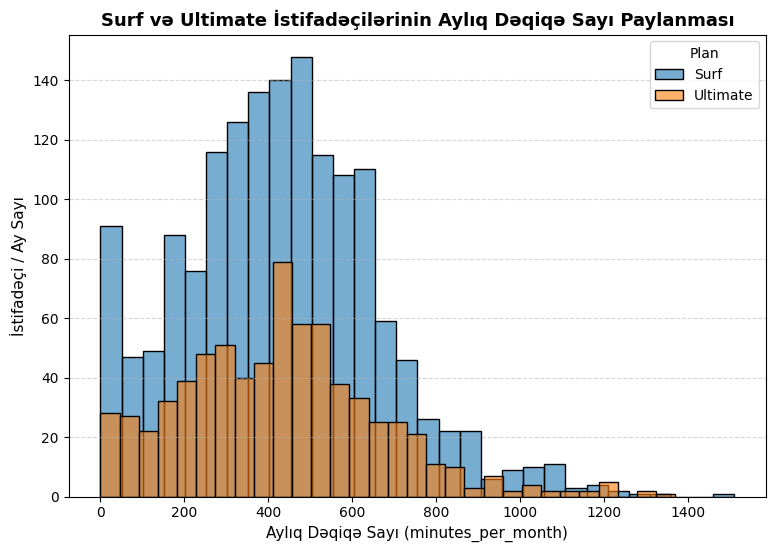

In [126]:
# Datanı planlara görə ayırırıq
surf_minutes = finaldata[finaldata['plan'] == 'surf']['minutes_per_month']
ultimate_minutes = finaldata[finaldata['plan'] == 'ultimate']['minutes_per_month']

# Qrafik ölçüsünü təyin edirik
plt.figure(figsize=(9, 6))

# Histoqramları üst-üstə çəkirik (edgecolor='black' qara çərçivələr üçün)
sns.histplot(surf_minutes, bins=30, label='Surf', alpha=0.6, edgecolor='black')
sns.histplot(ultimate_minutes, bins=30, label='Ultimate', alpha=0.6, edgecolor='black')

# Başlıq və ox adlarını dəqiqləşdiririk
plt.title('Surf və Ultimate İstifadəçilərinin Aylıq Dəqiqə Sayı Paylanması', fontsize=13, fontweight='bold')
plt.xlabel('Aylıq Dəqiqə Sayı (minutes_per_month)', fontsize=11)
plt.ylabel('İstifadəçi / Ay Sayı', fontsize=11)

# Legend (plan adları qutusu)
plt.legend(title='Plan')

# Arxa fon üçün grid xətləri
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Qrafiki göstəririk
plt.show()

Müxtəlif planlardakı istifadəçilərin zəngləri üçün fərqli davranışlara malik olub-olmadığını müəyyən etmək üçün zəng müddətinin orta və dəyişənini hesablayaq

In [127]:
finaldata.groupby('plan')['minutes_per_month'].agg(['mean', 'var'])


,mean,var
plan,,
surf,428.749523,54968.279461
ultimate,430.450000,57844.464812


buna boxplotda baxaq

/tmp/ipykernel_5719/2632984027.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='plan', y='minutes_per_month', data=finaldata, palette='Set2')


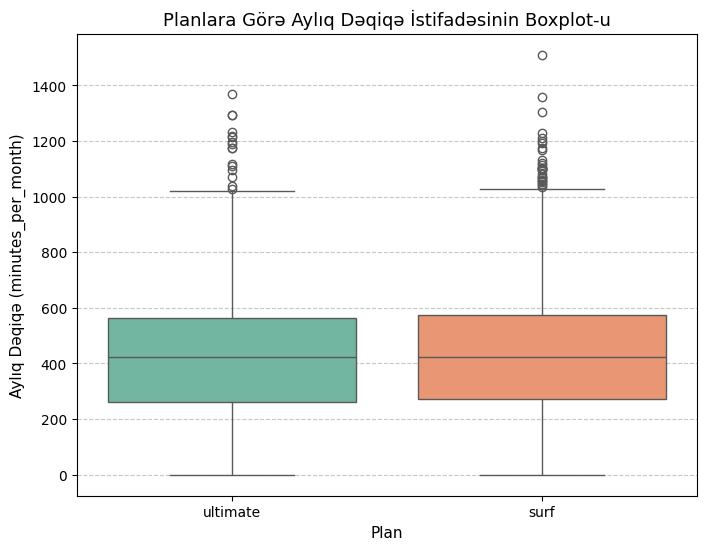

In [128]:
# Plot a boxplot to visualize the distribution of the monthly call duration
import seaborn as sns

plt.figure(figsize=(8, 6))

# Boxplot qururuq
sns.boxplot(x='plan', y='minutes_per_month', data=finaldata, palette='Set2')

# Başlıq və ox adları
plt.title('Planlara Görə Aylıq Dəqiqə İstifadəsinin Boxplot-u', fontsize=13)
plt.xlabel('Plan', fontsize=11)
plt.ylabel('Aylıq Dəqiqə (minutes_per_month)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()


###Surf planının istifadəçiləri üçün tətbiq olunan 500 dəqiqəlik limit əksər istifadəçilər üçün yetərlidir, lakin onların azı 30-40%-i limiti aşaraq əlavə ödəniş edir. Ultimate istifadəçiləri isə verilən 3000 dəqiqəlik limitin çox kiçik bir hissəsini (orta hesabla ~430 dəqiqəsini) istifadə edirlər.

In [129]:
finaldata.groupby('plan')['minutes_per_month'].describe()


,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
surf,1573.0,428.749523,234.453150,0.0,272.0,425.0,576.00,1510.0
ultimate,720.0,430.450000,240.508762,0.0,260.0,424.0,565.25,1369.0


### Hər iki plan istifadəçilərinin orta danışıq müddəti demek olar ki bir birinə çox yaxındır. Median göstəricisinin ~$428$ dəqiqə olduğunu nəzərə alsaq, Surf istifadəçilərinin təxminən 35 40%-i hər ay bu 500 dəqiqəlik limiti aşır və əlavə dəqiqə haqqı  ödəyir. Bu da şirkət üçün əlavə gəlir mənbəyi yaradır

###Ultimate planında pulsuz zəng limiti 3000 dəqiqədir.İstifadəçilərin orta hesabla yalnız $430$ dəqiqə danışdığını və maksimum göstəricilərin belə 1400 1500 dəqiqəni keçmədiyini nəzərə alsaq, heç bir Ultimate istifadəçisi öz zəng limitini aşmır. Limit istifadəçilərin ehtiyacından qat-qat böyükdür.

### Messages

In [130]:
# Hər planın istifadəçilərinin hər ay göndərməyə meylli mesajlarının sayını müqayisə edin

finaldata.groupby(['month','plan'])['message_per_month'].sum().head().reset_index()


,month,plan,message_per_month
0,1.0,surf,21.0
1,1.0,ultimate,62.0
2,2.0,surf,108.0
3,2.0,ultimate,151.0
4,3.0,surf,351.0


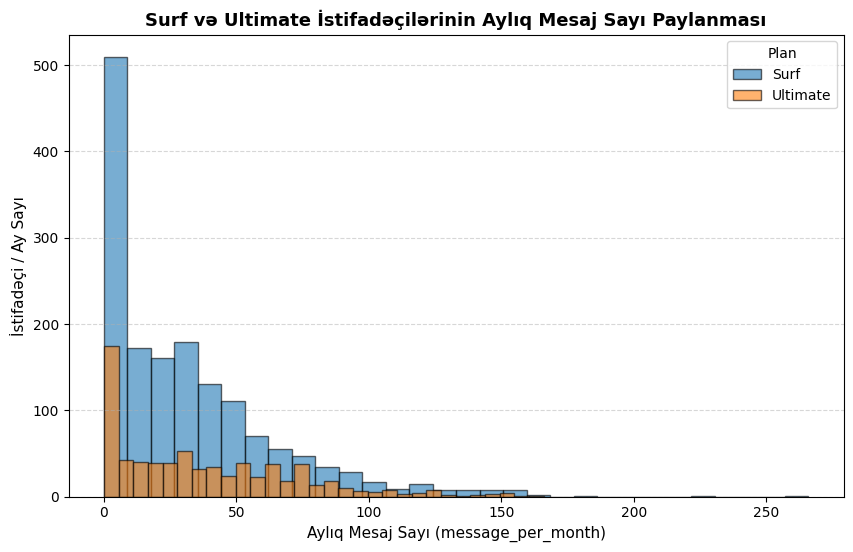

In [131]:
# 1. Məlumatları planlara görə ayırırıq
surf_messages = finaldata[finaldata['plan'] == 'surf']['message_per_month']
ultimate_messages = finaldata[finaldata['plan'] == 'ultimate']['message_per_month']

# 2. Qrafik ölçüsünü təyin edirik
plt.figure(figsize=(10, 6))

# 3. Histoqramları çəkirik (edgecolor='black' ilə qara çərçivələr əlavə olunur)
plt.hist(surf_messages, bins=30, alpha=0.6, color='#1f77b4', label='Surf', edgecolor='black')
plt.hist(ultimate_messages, bins=30, alpha=0.6, color='#ff7f0e', label='Ultimate', edgecolor='black')

# 4. Başlıq, ox adları və xətkeş (grid) əlavə edirik
plt.title('Surf və Ultimate İstifadəçilərinin Aylıq Mesaj Sayı Paylanması', fontsize=13, fontweight='bold')
plt.xlabel('Aylıq Mesaj Sayı (message_per_month)', fontsize=11)
plt.ylabel('İstifadəçi / Ay Sayı', fontsize=11)
plt.legend(title='Plan', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 5. Qrafiki göstəririk
plt.show()

In [132]:
# Aylıq mesajların ortalamasını və variasiiyasini hesablayaq

finaldata.groupby('plan')['message_per_month'].agg(['mean', 'var'])

,mean,var
plan,,
surf,31.159568,1126.724522
ultimate,37.551389,1208.756744


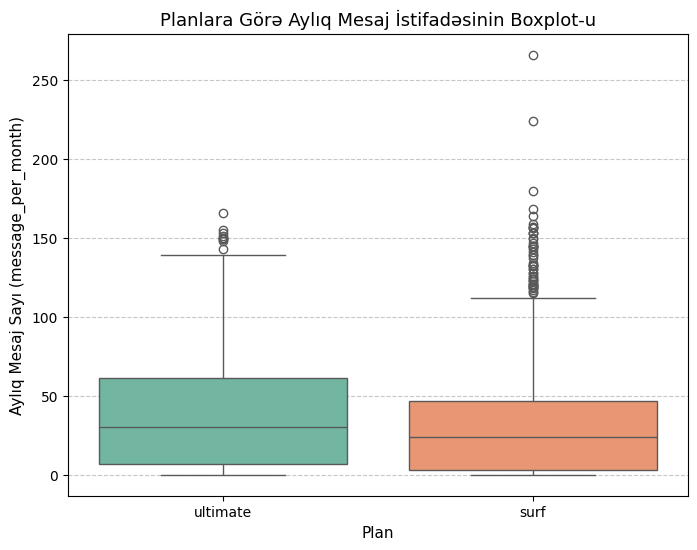

In [133]:
# Qrafik ölçüsünü təyin edirik
plt.figure(figsize=(8, 6))

# Boxplot çəkirik (xəbərdarlıq verməməsi üçün hue və legend parametrləri əlavə olunub)
sns.boxplot(
    x='plan',
    y='message_per_month',
    data=finaldata,
    hue='plan',
    palette='Set2',
    legend=False
)

# Başlıq və ox adlarını eyni üslubda təyin edirik
plt.title('Planlara Görə Aylıq Mesaj İstifadəsinin Boxplot-u', fontsize=13)
plt.xlabel('Plan', fontsize=11)
plt.ylabel('Aylıq Mesaj Sayı (message_per_month)', fontsize=11)

# Arxa fona qırıq-qırıq xətlər (grid) əlavə edirik
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Qrafiki göstəririk
plt.show()

In [134]:
finaldata.groupby('plan')['message_per_month'].describe()

,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
surf,1573.0,31.159568,33.566717,0.0,3.0,24.0,47.0,266.0
ultimate,720.0,37.551389,34.767179,0.0,7.0,30.0,61.0,166.0


###hər iki qrupda istifadəçilərin böyük əksəriyyəti ayda 60-dan az mesaj göndərir.Surf planının 50 mesajlıq pulsuz limitini istifadəçilərin yalnız 25%-i keçir, Ultimate planında isə 1000 SMS-lik limitin dörddə birinə çatacaq qədər belə mesaj göndərən olmur.Surf planında 100-dən çox mesaj göndərən normadan kənar (outlier) istifadəçilərin sayı Ultimate-ə nəzərən daha çoxdur və maksimum göstərici 266 mesaj təşkil edir.

### Internet

In [135]:
finaldata.groupby(['month','plan'])['gb_used'].sum().head().reset_index()

,month,plan,gb_used
0,1.0,surf,10.0
1,1.0,ultimate,29.0
2,2.0,surf,110.0
3,2.0,ultimate,121.0
4,3.0,surf,312.0


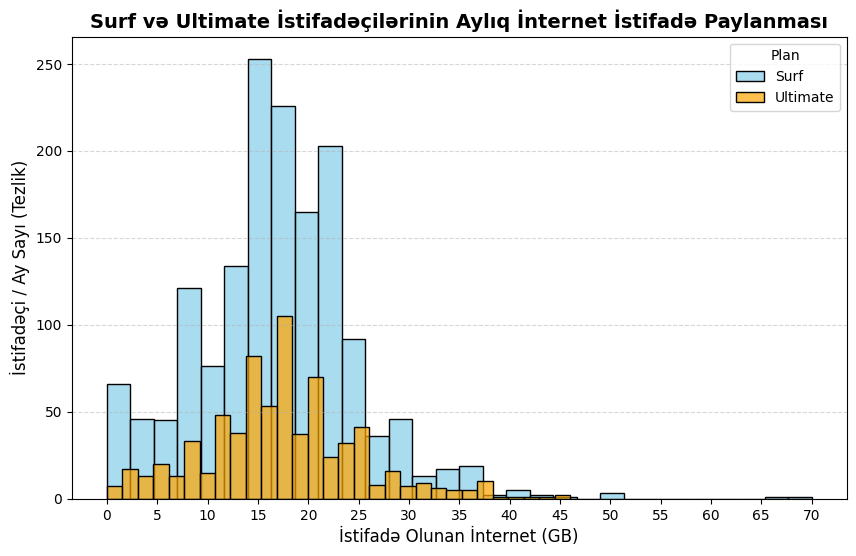

In [136]:
# Datanı planlara görə ayırırıq
surf_internet = finaldata[finaldata['plan'] == 'surf']['gb_used']
ultimate_internet = finaldata[finaldata['plan'] == 'ultimate']['gb_used']

# Qrafik ölçüsü
plt.figure(figsize=(10, 6))

# Seaborn histplot ilə iki planı bir qrafikdə çəkirik
sns.histplot(surf_internet, bins=30, label='Surf', color='skyblue', alpha=0.7, edgecolor='black', kde=False)
sns.histplot(ultimate_internet, bins=30, label='Ultimate', color='orange', alpha=0.7, edgecolor='black', kde=False)

# Dizayn
plt.title('Surf və Ultimate İstifadəçilərinin Aylıq İnternet İstifadə Paylanması', fontsize=14, fontweight='bold')
plt.xlabel('İstifadə Olunan İnternet (GB)', fontsize=12)
plt.ylabel('İstifadəçi / Ay Sayı (Tezlik)', fontsize=12)
plt.legend(title='Plan')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# X oxundakı şkalanı daha dəqiq göstərmək üçün
plt.xticks(range(0, int(finaldata['gb_used'].max()) + 5, 5))

plt.show()

In [137]:
#Aylıq internet trafikinin ortalamasını və variasiyasini hesablayın

finaldata.groupby('plan')['gb_used'].agg(['mean', 'var'])

,mean,var
plan,,
surf,16.670693,61.58360
ultimate,17.306944,58.83055


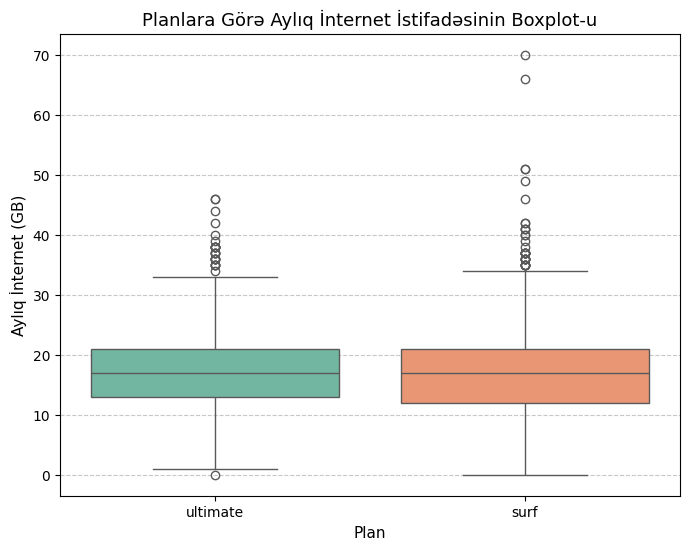

In [138]:
# 1. Qrafik ölçüsünü təyin edirik
plt.figure(figsize=(8, 6))

# 2. İnternet istifadəsi üçün Boxplot çəkirik
sns.boxplot(
    x='plan',
    y='gb_used',
    data=finaldata,
    hue='plan',
    palette='Set2',
    legend=False
)

# 3. Başlıq və ox adlarını dəqiqləşdiririk
plt.title('Planlara Görə Aylıq İnternet İstifadəsinin Boxplot-u', fontsize=13)
plt.xlabel('Plan', fontsize=11)
plt.ylabel('Aylıq İnternet (GB)', fontsize=11)

# 4. Arxa fona qırıq-qırıq xətlər (grid) əlavə edirik
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 5. Qrafiki göstəririk
plt.show()

In [139]:
finaldata.groupby('plan')['gb_used'].describe()

,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
surf,1573.0,16.670693,7.847522,0.0,12.0,17.0,21.0,70.0
ultimate,720.0,17.306944,7.670108,0.0,13.0,17.0,21.0,46.0


###Həm Surf, həm də Ultimate istifadəçilərinin aylıq median internet istifadəsi eynidir (17 GB) və hər iki grupta istifadəçilərin yarıdan çoxu ayda 12-21 GB arası internet işlədir.Surf planında daxil olan paket 15 GB olduğu üçün istifadəçilərin yarıdan çoxu (50%-dən çoxu) limiti aşaraq əlavə ödəniş edir.Ultimate planında paket 30 GB olduğundan istifadəçilərin böyük əksəriyyəti limit daxilində qalır, yalnız az sayda kənarlaşmalar (outliers) 30 GB-ı keçir.

## Revenue

In [140]:
finaldata.groupby(['month','plan'])['revenue'].sum().head().reset_index()

,month,plan,revenue
0,1.0,surf,40.00
1,1.0,ultimate,280.00
2,2.0,surf,309.57
3,2.0,ultimate,490.00
4,3.0,surf,1056.65


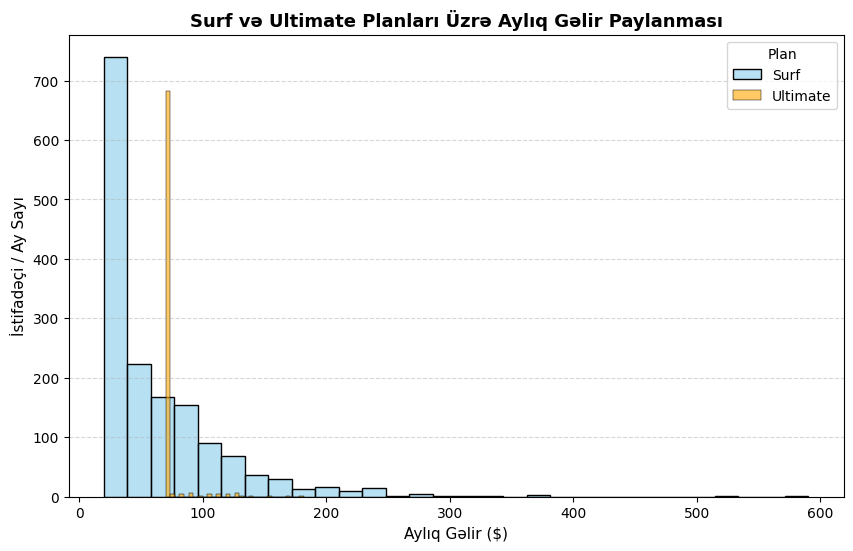

In [141]:
surf_revenue = finaldata[finaldata['plan'] == 'surf']['revenue']
ultimate_revenue = finaldata[finaldata['plan'] == 'ultimate']['revenue']

# Qrafik ölçüsü
plt.figure(figsize=(10, 6))

# Çərçivəsi qara olan histoqramlar
sns.histplot(surf_revenue, bins=30, label='Surf', color='skyblue', alpha=0.6, edgecolor='black')
sns.histplot(ultimate_revenue, bins=30, label='Ultimate', color='orange', alpha=0.6, edgecolor='black')

# Dizayn və başlıqlar
plt.title('Surf və Ultimate Planları Üzrə Aylıq Gəlir Paylanması', fontsize=13, fontweight='bold')
plt.xlabel('Aylıq Gəlir ($)', fontsize=11)
plt.ylabel('İstifadəçi / Ay Sayı', fontsize=11)
plt.legend(title='Plan')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [142]:

finaldata.groupby('plan')['revenue'].agg(['mean', 'var'])

,mean,var
plan,,
surf,60.551729,3062.446864
ultimate,72.301105,129.159556


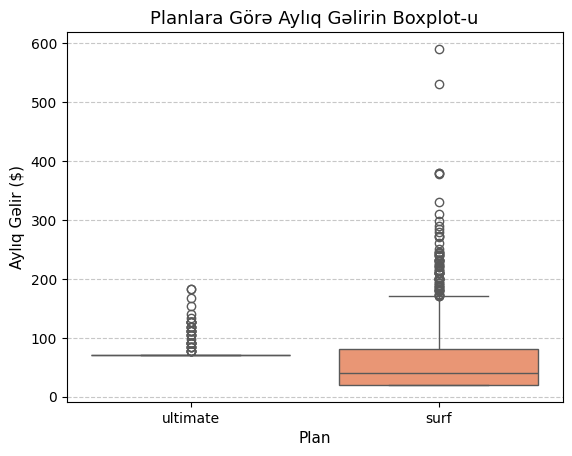

In [143]:
# 2. Gəlir üçün Boxplot çəkirik (xəbərdarlıq verməməsi üçün hue və legend tənzimlənib)
sns.boxplot(
    x='plan',
    y='revenue',
    data=finaldata,
    hue='plan',
    palette='Set2',
    legend=False
)

# 3. Başlıq və ox adlarını qoyuruq
plt.title('Planlara Görə Aylıq Gəlirin Boxplot-u', fontsize=13)
plt.xlabel('Plan', fontsize=11)
plt.ylabel('Aylıq Gəlir ($)', fontsize=11)

# 4. Arxa fona qırıq-qırıq xətlər (grid) əlavə edirik
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 5. Qrafiki göstəririk
plt.show()

In [144]:
finaldata.groupby('plan')['revenue'].describe()

,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
surf,1579.0,60.551729,55.339379,20.0,20.0,40.18,80.315,590.37
ultimate,724.0,72.301105,11.364839,70.0,70.0,70.00,70.000,182.00


###Ultimate planında median, 25% və 75% kvantillər tam eynidir 70$, çünki istifadəçilərin demək olar ki, hamısı sabit abonement haqqı ödəyir və limitləri aşmır.

###Surf planının ayliq haqqı ucuz  olsa da, istifadəçilərin 50%-dən çoxu limitləri aşdığı üçün orta gəlir 60.55 a catir və hətta 590 $-a çatan çoxlu kənarlaşmalar (outliers) var.

###Ultimate planı birbaşa daha yüksək orta gəlir 72.3 təmin etsə də, Surf planı əlavə xidmət ödənişləri hesabına böyük gəlir dəyişkənliyi və yüksək qazanc potensialı göstərir.

## Statistik fərziyyələri sınayaq

Ultimate və Surf zəng planlarının istifadəçilərindən əldə edilən orta gəlirin fərqli olduğu fərziyyəsini sınaqdan keçirək


$H_0$ (Nul fərziyyə): Surf və Ultimate tarif planı istifadəçilərinin orta gəliri bərabərdir (fərq yoxdur).
$H_1$ (Alternativ fərziyyə): Surf və Ultimate tarif planı istifadəçilərinin orta gəliri fərqlənir.

In [145]:
#Əvvəlcə surf və ultimate planlarından gələn gəliri ayiraq
surf_revenue=finaldata[finaldata['plan'] == 'surf']['revenue']
ultimate_revenue=finaldata[finaldata['plan'] == 'ultimate']['revenue']
print(surf_revenue)
print(ultimate_revenue)

1        20.00
2        20.00
3        90.09
4        60.00
5        60.00
         ...  
2298    100.00
2299     20.00
2300     70.00
2301     40.00
2302     90.00
Name: revenue, Length: 1579, dtype: float64
0       70.0
19      70.0
20      84.0
26      70.0
27      70.0
        ... 
2268    70.0
2269    70.0
2270    70.0
2271    70.0
2287    70.0
Name: revenue, Length: 724, dtype: float64


In [146]:
# Alfa dəyəri (əhəmiyyətlilik dərəcəsi)
alpha = 0.05

# 1. SHAPIRO-WILK TESTİ (Normallığın yoxlanılması)
stat_surf, p_surf = stats.shapiro(surf_revenue)
stat_ult, p_ult = stats.shapiro(ultimate_revenue)

print(f"Surf üçün Shapiro-Wilk p-value: {p_surf}")
print(f"Ultimate üçün Shapiro-Wilk p-value: {p_ult}\n")

# 2. İKİ NÜMUNƏLİ WELCH T-TESTİ (Orta gəlirlərin müqayisəsi)
results = stats.ttest_ind(surf_revenue, ultimate_revenue, equal_var=False)

print(f"t-statistikası: {results.statistic}")
print(f"p-value nəticəsi: {results.pvalue}\n")

# Yekun Nəticə
if results.pvalue < alpha:
    print("Nəticə: Nul fərziyyə (H0) RƏDD EDİLİR.")
    print("Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli FƏRQ VAR.")
else:
    print("Nəticə: Nul fərziyyə (H0) rədd edilə BİLMƏDİ.")
    print("Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli fərq YOXDUR.")

Surf üçün Shapiro-Wilk p-value: 1.1957022619422507e-44
Ultimate üçün Shapiro-Wilk p-value: 1.0542410667213706e-47

t-statistikası: -8.073538160306446
p-value nəticəsi: 1.218411585212325e-15

Nəticə: Nul fərziyyə (H0) RƏDD EDİLİR.
Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli FƏRQ VAR.


### Alfa dəyər təyin edib shapiro testi edək

In [147]:
from scipy import stats

# Alfanı 0.05 götüək
alpha = 0.05

# Shapiro testi edək
stat_surf, p_surf = stats.shapiro(surf_revenue)
stat_ult ,p_ult = stats.shapiro(ultimate_revenue)
print(f"Surf üçün Shapiro-Wilk p-value: {p_surf}")
print(f"Ultimate üçün Shapiro-Wilk p-value: {p_ult}")


Surf üçün Shapiro-Wilk p-value: 1.1957022619422507e-44
Ultimate üçün Shapiro-Wilk p-value: 1.0542410667213706e-47


hər ikisi üçün p value 0.05 dən kiçikdirsə deməli bu normal paylanma deyil qeyri normal paylanmadır. qeyri normal paylanmalar üçün olan testlərdən isə iki fərqli qrup üçün olan t-testini testini edek. bu testin nəticəsində aldığımız p value secdiyimiz alfa dəyərindən kiçik olarsa hər iki Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli FƏRQ VAR. və birinci H0 hipotezimiz gəğv edilir. əgər boyukdürsə o zaman H1 hipotezimiz leğv edilir və hər iki plandan gələn gəlir arasinda FƏRQ YOXDUR

In [148]:
# 2. İKİ NÜMUNƏLİ WELCH T-TESTİ (Orta gəlirlərin müqayisəsi)
results = stats.ttest_ind(surf_revenue, ultimate_revenue, equal_var=False)

print(f"t-statistikası: {results.statistic}")
print(f"p-value nəticəsi: {results.pvalue}\n")

# Yekun Nəticə
if results.pvalue < alpha:
    print("Nəticə: Nul fərziyyə (H0) RƏDD EDİLİR.")
    print("Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli FƏRQ VAR.")
else:
    print("Nəticə: Nul fərziyyə (H0) rədd edilə BİLMƏDİ.")
    print("Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli fərq YOXDUR.")

t-statistikası: -8.073538160306446
p-value nəticəsi: 1.218411585212325e-15

Nəticə: Nul fərziyyə (H0) RƏDD EDİLİR.
Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli FƏRQ VAR.


# 2. İKİ NÜMUNƏLİ WELCH T-TESTİ (Orta gəlirlərin müqayisəsi)
results = stats.ttest_ind(surf_revenue, ultimate_revenue, equal_var=False)

print(f"t-statistikası: {results.statistic}")
print(f"p-value nəticəsi: {results.pvalue}\n")

# Yekun Nəticə
if results.pvalue < alpha:
    print("Nəticə: Nul fərziyyə (H0) RƏDD EDİLİR.")
    print("Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli FƏRQ VAR.")
else:
    print("Nəticə: Nul fərziyyə (H0) rədd edilə BİLMƏDİ.")
    print("Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli fərq YOXDUR.")

### Nəticə 0.05 dən kiçikdir deməli H0 hipotezi redd edilir ve H1 hipotezi doğrudur Surf və Ultimate planlarının orta gəlirləri arasında statistik olaraq əhəmiyyətli FƏRQ VAR.

#NY-Nyu-Cersi bölgəsindəki istifadəçilərdən əldə edilən orta gəlirin digər bölgələrdəki istifadəçilərin gəlirindən fərqli olduğu fərziyyəsini sınaqdan keçirək

$H_0$ (Nul fərziyyə): NY-NJ ərazisindəki istifadəçilərin və digər regionlardakı istifadəçilərin aylıq orta gəliri bərabərdir (fərq yoxdur).
$H_1$ (Alternativ fərziyyə): NY-NJ ərazisindəki istifadəçilərin və digər regionlardakı istifadəçilərin aylıq orta gəliri fərqlənir.

In [149]:
#Məlumatları 2 qrupa ayırırıq
ny_nj_revenue = finaldata[finaldata['city'].str.contains('NY-NJ', na=False)]['revenue']
other_revenue = finaldata[~finaldata['city'].str.contains('NY-NJ', na=False)]['revenue']
print(ny_nj_revenue)
print(other_revenue)

56       20.00
57       38.84
75       20.00
76      100.00
77       20.00
         ...  
2294     70.00
2295    100.00
2296     80.00
2297     60.00
2298    100.00
Name: revenue, Length: 378, dtype: float64
0       70.00
1       20.00
2       20.00
3       90.09
4       60.00
        ...  
2287    70.00
2299    20.00
2300    70.00
2301    40.00
2302    90.00
Name: revenue, Length: 1925, dtype: float64


In [150]:

#Alfa təyin edirik
alpha = 0.05
#SHAPIRO-WILK TESTİ (Normallığın yoxlanılması)
stat_ny, p_ny = stats.shapiro(ny_nj_revenue)
stat_oth, p_oth = stats.shapiro(other_revenue)

print(f"NY-NJ üçün Shapiro-Wilk p-value: {p_ny}")
print(f"Digər regionlar üçün Shapiro-Wilk p-value: {p_oth}")


NY-NJ üçün Shapiro-Wilk p-value: 8.867602606934685e-20
Digər regionlar üçün Shapiro-Wilk p-value: 1.3250899606350068e-47


### Hər ikisi üçün p value 0.05 dən kiçikdir bu o dmekdir ki bu qeyri normal paylanmadir ve bundan sonra qeyri normal paylanmalar ve ferqli qrup ucun olan Man Whitney U testini seçək

In [151]:
#MANN-WHITNEY U TESTİ
results_city_mw = stats.mannwhitneyu(ny_nj_revenue, other_revenue)
results_city_mw.pvalue

np.float64(0.005223180878362673)

###results_city_mw.pvalue 0.05 dən kiçikdir bu o dmekdir ki h0 hipotezi redd edilir və H1 hipotezi doğrudur yəni  NY-NJ ərazisindəki istifadəçilərin və digər regionlardakı istifadəçilərin aylıq orta gəliri fərqlənir.




In [152]:
ny_nj_revenue = finaldata[finaldata['city'].str.contains('NY-NJ', na=False)]['revenue'].sum()
other_revenue = finaldata[~finaldata['city'].str.contains('NY-NJ', na=False)]['revenue'].sum()
print(ny_nj_revenue)
print(other_revenue)

22660.35
125296.83000000002


NY-NJ regionu üçün umumi gelir 22660.35
Digər regionlar üçün ümumi gəlir 125296.83 dir
demeli Digər regionlar üçün ümumi gəlir NY- NJ regionu üçün olan ümumi gəlirdən təqribən 5 dəfə çoxdur

#Ümumi nəticə



###Məlumatların Hazırlanması (Data Preprocessing):Məlumatlar təmizləndi, buraxılmış dəyərlər (eksik veriler) dolduruldu və tip xətaları düzəldildi.Aylıq zəng müddətləri yuvarlaqlaşdırıldı, internet istifadəsi (MB) GB-a çevrildi.

###İstifadəçi Davranışlarının Analizi (EDA):Zəng və Mesajlar: Surf və Ultimate istifadəçilərinin aylıq zəng müddətləri (430 dəq) və mesaj sayı (30-38 SMS) demək olar ki, eynidir.İnternet: Hər iki tarifin istifadəçiləri orta hesabla ayda 17 GB internet işlədir. Surf istifadəçilərinin yarıdan çoxu 15 GB-lıq limiti aşıb əlavə ödəniş edir.

###Gəlir Analizi (Revenue):Surf planı: Baza qiyməti ucuz 20 dollar olsa da, limit aşmaları hesabına orta aylıq gəlir 60.55 dollara  yüksəlir.Ultimate planı: Baza qiyməti 70 dolllardir və istifadəçilər limitləri aşmadığı üçün sabit, təxmin edilə bilən gəlir 72.3 dollar təmin edir.

###Hipotez Testlərinin Nəticəsi:Planlar arası gəlir: Shapiro twstinin neticesinde qeyri normal paylanma olduğuna qerar verdik ve buna uygun Man Whitney U test nəticəsində p < 0.05 Surf və Ultimate planlarının orta gəlirləri arasında əhəmiyyətli fərq olduğu sübut olundu.Regionlar arası gəlir: NY-NJ bölgesi ilə digər regionların gəliri arasında da  əhəmiyyətli fərq var .

###Biznes Tövsiyəsi :Şirkət reklam büdcəsini Ultimate planına yönəltməlidir. Çünki Ultimate istifadəçiləri şəbəkəni həddindən artıq yükləmədən şirkətə sabit və daha yüksək 70 dollar gəlir gətirir.

## 💡 Biznes Tövsiyələri:

1. **Reklam Büdcəsinin Yönləndirilməsi:** Reklam büdcəsinin daha çox Surf tarifinin təşviqinə və ya intermediate (orta) yeni bir tarifin yaradılmasına ayrılması tövsiyə olunur.
2. **Aralıq Tarif Planının Yaradılması:** Surf və Ultimate arasında (məsələn, 20 GB internet və $40-45 qiymət aralığında) yeni tarif planı təklif etməklə müştəri məmnuniyyəti artırıla bilər.
3. **İnternet Paketlərinə Fokuslanma:** SMS paketlərinin limitini azaldıb, diqqəti daha cəlbedici internet paketlərinə və əlavə GB təkliflərinə yönəltmək lazımdır.
4. **Surf Müştərilərinin Monetizasiyası:** Surf istifadəçilərinə limit aşımı zamanı əlavə GB-ları paket şəklində daha uyğun qiymətə almaq imkanı sunularaq ARPU artırıla bilər.
5. **Churn (Müştəri İtkisi) Riskini Azaltmaq:** Surf tarifində yüksək limit aşımı ödənişi edən narazı müştəriləri Ultimate və ya xüsusi endirimli paketlərə yönəltməklə onları sistemdə saxlamaq olar.